# 03 – Deep models

MLP, 1D CNN and LSTM trained on the raw heartbeat signal. No class-imbalance handling is used here; that is studied separately on the best model. All results are on the **validation set**.

Common settings: Adam (lr = 0.001), sparse categorical cross-entropy, batch size 128, up to 50 epochs, early stopping on validation macro F1 (patience 8, best weights restored), ReduceLROnPlateau on validation loss (factor 0.5, patience 4).

In [1]:
import os
import sys
sys.path.append("..")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_mitbih, split_train_val, SEED
from src.models import build_mlp, build_simple_cnn, build_resnet_cnn, build_lstm
from src.train import set_seed, train_model
from src.evaluate import (compute_metrics, per_class_table, summary_row, save_results,
                          plot_confusion_matrix, plot_history, FIG_DIR, RESULTS_DIR)

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

In [2]:
X_train, y_train = load_mitbih("train")
X_tr, X_val, y_tr, y_val = split_train_val(X_train, y_train)
print("Train:", X_tr.shape, " Validation:", X_val.shape)

results = {}

Train: (70043, 187)  Validation: (17511, 187)


## 1. MLP

Dense(256) → Dropout(0.3) → Dense(128) → Dropout(0.3) → Dense(5, softmax). Every input sample is connected to every neuron, so the network has no notion of time order or local shape.

In [3]:
set_seed(SEED)
mlp = build_mlp()
mlp.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 187)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        48,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,669 (319.02 KB)

 Trainable params: 81,669 (319.02 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history, train_time = train_model(mlp, X_tr, y_tr, X_val, y_val)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


548/548 - 2s - 3ms/step - accuracy: 0.9095 - loss: 0.3271 - val_accuracy: 0.9475 - val_loss: 0.1862 - val_macro_f1: 0.6994 - learning_rate: 0.0010


Epoch 2/50


548/548 - 1s - 2ms/step - accuracy: 0.9455 - loss: 0.1947 - val_accuracy: 0.9581 - val_loss: 0.1494 - val_macro_f1: 0.7857 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 47/50


548/548 - 1s - 2ms/step - accuracy: 0.9853 - loss: 0.0480 - val_accuracy: 0.9813 - val_loss: 0.0676 - val_macro_f1: 0.9031 - learning_rate: 1.2500e-04


Epoch 48/50


548/548 - 1s - 2ms/step - accuracy: 0.9845 - loss: 0.0480 - val_accuracy: 0.9813 - val_loss: 0.0672 - val_macro_f1: 0.9038 - learning_rate: 1.2500e-04


Training time: 45 s


In [5]:
y_pred = mlp.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "MLP", "layers": [256, 128], "dropout": 0.3, "lr": 1e-3, "batch_size": 128,
          "max_epochs": 50, "epochs_trained": len(history.history["loss"]),
          "class_weight": None, "seed": SEED, "train_time_s": round(train_time, 1)}
save_results("mlp", metrics, params, history.history)
mlp.save(MODEL_DIR / "mlp.keras")
results["mlp"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.904


,precision,recall,f1,support
N,0.984,0.995,0.990,14494.0
S,0.929,0.708,0.804,445.0
V,0.959,0.934,0.946,1158.0
F,0.877,0.727,0.795,128.0
Q,0.984,0.985,0.985,1286.0


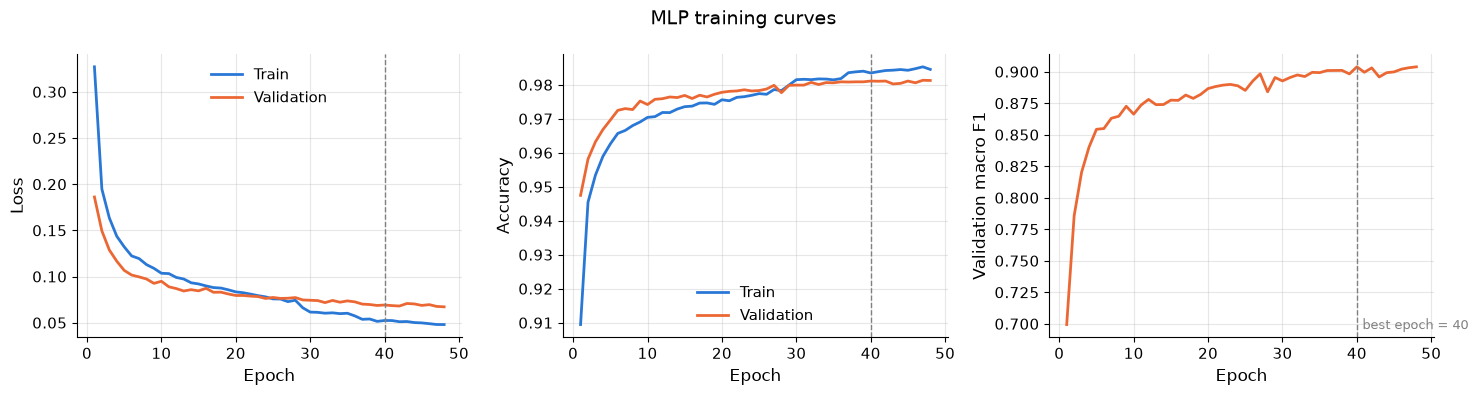

In [6]:
fig = plot_history(history.history, "MLP training curves")
fig.savefig(FIG_DIR / "history_mlp.png", dpi=200)
plt.show()

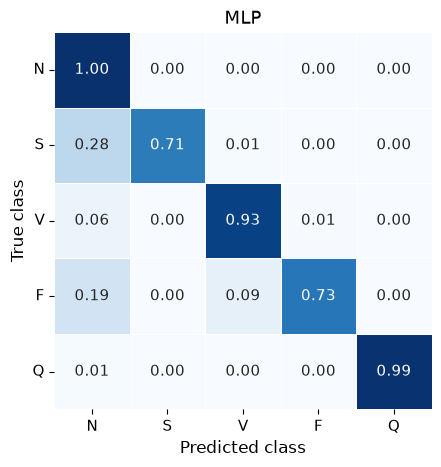

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "MLP", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_mlp.png", dpi=200)
plt.show()

## 2. Simple 1D CNN

Three blocks of Conv1D (kernel size 5, ReLU) + MaxPooling1D(2) with 32, 64 and 128 filters, then Flatten → Dense(64) → Dropout(0.3) → Dense(5, softmax). The convolution filters slide along the signal, so the same local shape (e.g. a sharp QRS peak) is detected wherever it appears.

In [8]:
set_seed(SEED)
simple_cnn = build_simple_cnn()
simple_cnn.summary()

Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 187)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 23, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2944)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       188,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,389 (939.02 KB)

 Trainable params: 240,389 (939.02 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history, train_time = train_model(simple_cnn, X_tr, y_tr, X_val, y_val)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


548/548 - 5s - 10ms/step - accuracy: 0.9260 - loss: 0.2745 - val_accuracy: 0.9629 - val_loss: 0.1267 - val_macro_f1: 0.7971 - learning_rate: 0.0010


Epoch 2/50


548/548 - 4s - 8ms/step - accuracy: 0.9645 - loss: 0.1314 - val_accuracy: 0.9734 - val_loss: 0.0961 - val_macro_f1: 0.8582 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 29/50


548/548 - 5s - 9ms/step - accuracy: 0.9959 - loss: 0.0117 - val_accuracy: 0.9875 - val_loss: 0.0730 - val_macro_f1: 0.9250 - learning_rate: 1.2500e-04


Epoch 30/50


548/548 - 5s - 9ms/step - accuracy: 0.9961 - loss: 0.0119 - val_accuracy: 0.9880 - val_loss: 0.0691 - val_macro_f1: 0.9272 - learning_rate: 6.2500e-05


Training time: 138 s


In [10]:
y_pred = simple_cnn.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "SimpleCNN", "conv_filters": [32, 64, 128], "kernel_size": 5, "dense": 64,
          "dropout": 0.3, "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "class_weight": None, "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("simple_cnn", metrics, params, history.history)
simple_cnn.save(MODEL_DIR / "simple_cnn.keras")
results["simple_cnn"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.929


,precision,recall,f1,support
N,0.991,0.996,0.994,14494.0
S,0.934,0.820,0.873,445.0
V,0.964,0.964,0.964,1158.0
F,0.868,0.773,0.818,128.0
Q,0.995,0.993,0.994,1286.0


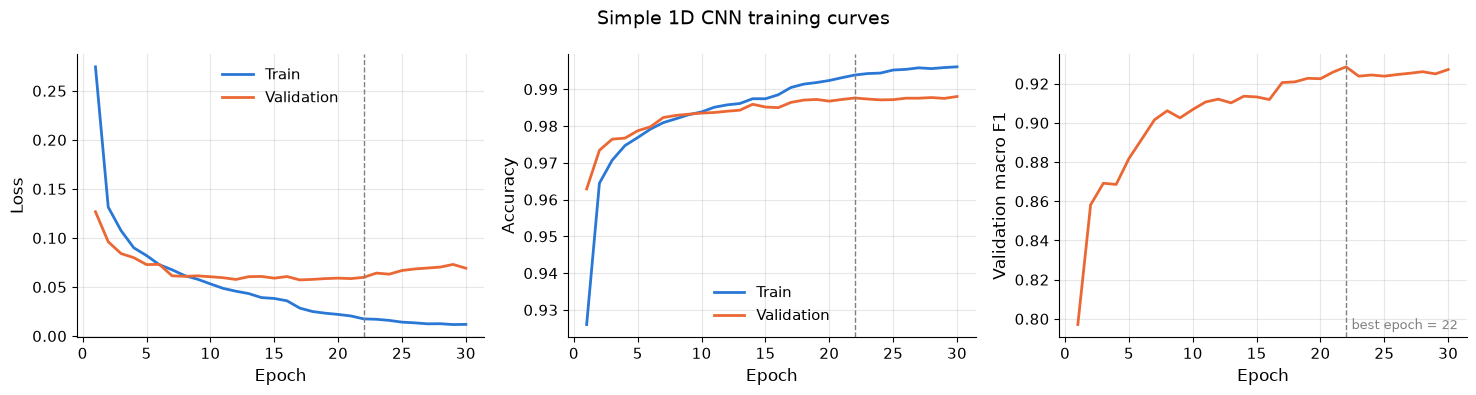

In [11]:
fig = plot_history(history.history, "Simple 1D CNN training curves")
fig.savefig(FIG_DIR / "history_simple_cnn.png", dpi=200)
plt.show()

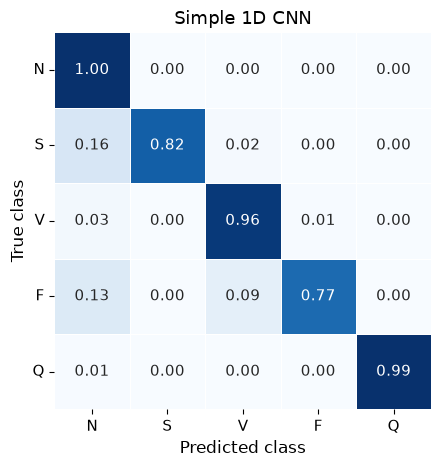

In [12]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Simple 1D CNN", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_simple_cnn.png", dpi=200)
plt.show()

## 3. Residual 1D CNN

Architecture based on Kachuee et al. (2018): Conv1D(32, 5) followed by five residual blocks [Conv1D → ReLU → Conv1D → add skip connection → ReLU → MaxPool(5, stride 2)], then Dense(32) → Dense(5, softmax). The skip connection lets each block learn only a correction to its input and helps gradients reach the early layers.

In [13]:
set_seed(SEED)
resnet_cnn = build_resnet_cnn()
resnet_cnn.summary()

Model: "resnet_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 187)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 187, 1)    │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 187, 32)   │        192 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 187, 32)   │      5,152 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 187, 32)   │      5,152 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 187, 32)   │          0 │ conv1d_5[0][0],   │
│                     │                   │            │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 187, 32)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 92, 32)    │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 92, 32)    │      5,152 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 92, 32)    │      5,152 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 92, 32)    │          0 │ conv1d_7[0][0],   │
│                     │                   │            │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 92, 32)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 44, 32)    │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 44, 32)    │      5,152 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 44, 32)    │      5,152 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 44, 32)    │          0 │ conv1d_9[0][0],   │
│                     │                   │            │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 44, 32)    │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 20, 32)    │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 20, 32)    │      5,152 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 20, 32)    │      5,152 │ conv1d_10[0][0] 

 Total params: 53,957 (210.77 KB)

 Trainable params: 53,957 (210.77 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history, train_time = train_model(resnet_cnn, X_tr, y_tr, X_val, y_val)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


548/548 - 9s - 16ms/step - accuracy: 0.9327 - loss: 0.2398 - val_accuracy: 0.9706 - val_loss: 0.1124 - val_macro_f1: 0.8366 - learning_rate: 0.0010


Epoch 2/50


548/548 - 7s - 12ms/step - accuracy: 0.9714 - loss: 0.1052 - val_accuracy: 0.9760 - val_loss: 0.0889 - val_macro_f1: 0.8603 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 32/50


548/548 - 6s - 11ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9885 - val_loss: 0.0830 - val_macro_f1: 0.9293 - learning_rate: 6.2500e-05


Epoch 33/50


548/548 - 6s - 11ms/step - accuracy: 0.9998 - loss: 8.6838e-04 - val_accuracy: 0.9885 - val_loss: 0.0849 - val_macro_f1: 0.9305 - learning_rate: 6.2500e-05


Training time: 220 s


In [15]:
y_pred = resnet_cnn.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "ResNetCNN", "n_blocks": 5, "filters": 32, "kernel_size": 5,
          "pool": "max(5, stride 2)", "dense": 32, "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "class_weight": None, "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("resnet_cnn", metrics, params, history.history)
resnet_cnn.save(MODEL_DIR / "resnet_cnn.keras")
results["resnet_cnn"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.933


,precision,recall,f1,support
N,0.994,0.995,0.994,14494.0
S,0.902,0.872,0.887,445.0
V,0.963,0.979,0.971,1158.0
F,0.890,0.758,0.819,128.0
Q,0.995,0.995,0.995,1286.0


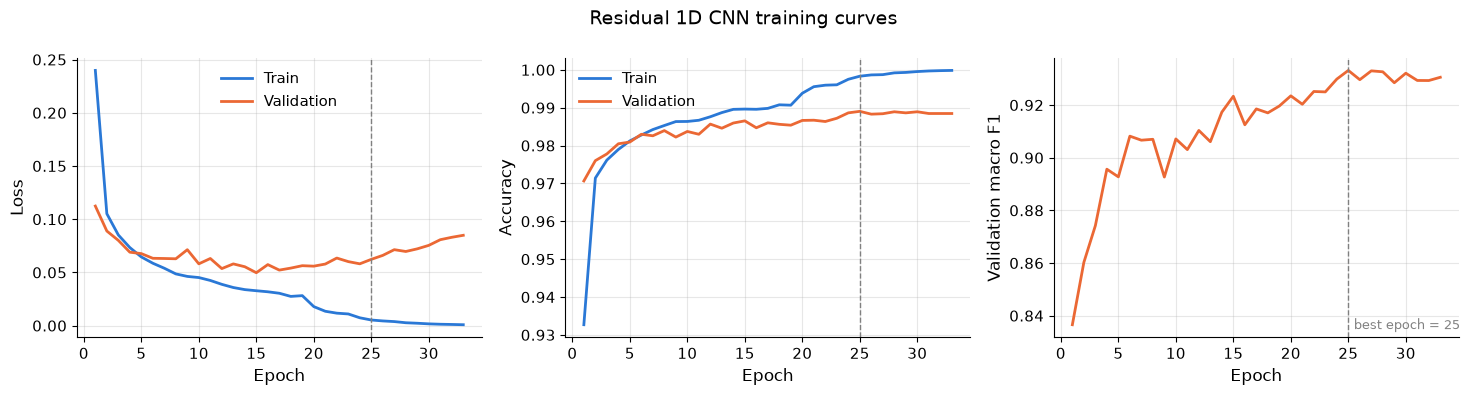

In [16]:
fig = plot_history(history.history, "Residual 1D CNN training curves")
fig.savefig(FIG_DIR / "history_resnet_cnn.png", dpi=200)
plt.show()

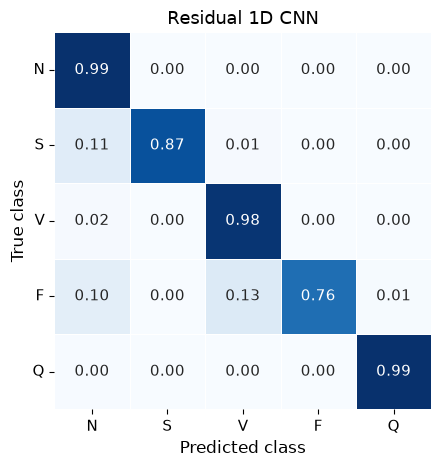

In [17]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Residual 1D CNN", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_resnet_cnn.png", dpi=200)
plt.show()

## 4. LSTM

Two stacked LSTM layers (64 units each) read the beat one sample at a time; the first returns the full sequence, the second only its final state. Then Dense(32) → Dense(5, softmax). The LSTM processes the 187 time steps sequentially, so training is much slower than for the CNNs.

In [18]:
set_seed(SEED)
lstm = build_lstm()
lstm.summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 187)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 187, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,165 (203.77 KB)

 Trainable params: 52,165 (203.77 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history, train_time = train_model(lstm, X_tr, y_tr, X_val, y_val)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


548/548 - 69s - 126ms/step - accuracy: 0.8267 - loss: 0.6791 - val_accuracy: 0.8277 - val_loss: 0.6467 - val_macro_f1: 0.1811 - learning_rate: 0.0010


Epoch 2/50


548/548 - 66s - 121ms/step - accuracy: 0.8281 - loss: 0.6447 - val_accuracy: 0.8277 - val_loss: 0.6335 - val_macro_f1: 0.1812 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 49/50


548/548 - 67s - 122ms/step - accuracy: 0.9823 - loss: 0.0602 - val_accuracy: 0.9803 - val_loss: 0.0717 - val_macro_f1: 0.8922 - learning_rate: 5.0000e-04


Epoch 50/50


548/548 - 66s - 121ms/step - accuracy: 0.9823 - loss: 0.0604 - val_accuracy: 0.9796 - val_loss: 0.0751 - val_macro_f1: 0.8850 - learning_rate: 5.0000e-04


Training time: 3342 s


In [20]:
y_pred = lstm.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "LSTM", "units": [64, 64], "dense": 32, "lr": 1e-3, "batch_size": 128,
          "max_epochs": 50, "epochs_trained": len(history.history["loss"]), "class_weight": None,
          "seed": SEED, "train_time_s": round(train_time, 1)}
save_results("lstm", metrics, params, history.history)
lstm.save(MODEL_DIR / "lstm.keras")
results["lstm"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.896


,precision,recall,f1,support
N,0.985,0.994,0.989,14494.0
S,0.890,0.692,0.779,445.0
V,0.951,0.945,0.948,1158.0
F,0.898,0.688,0.779,128.0
Q,0.983,0.987,0.985,1286.0


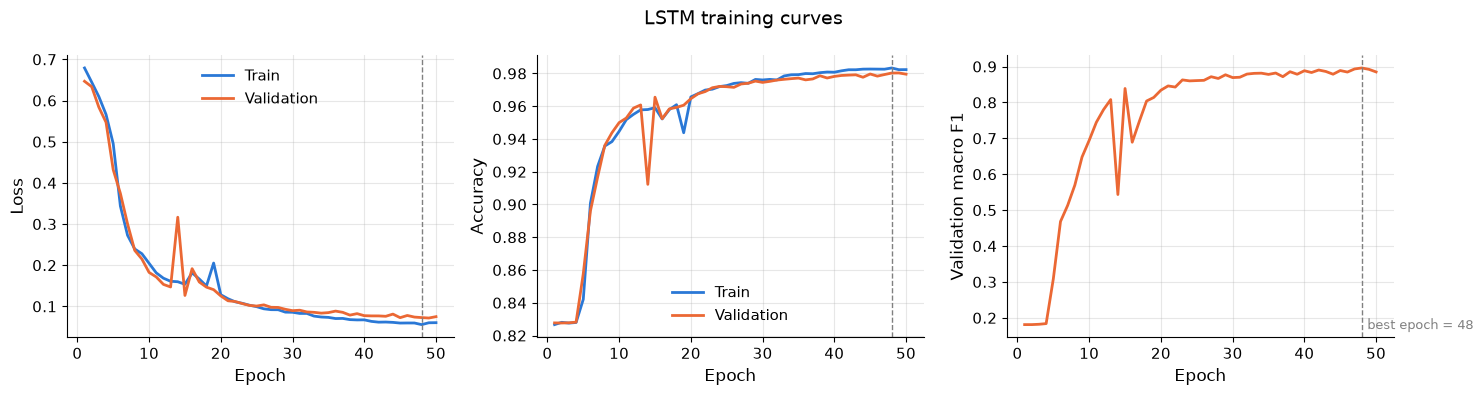

In [21]:
fig = plot_history(history.history, "LSTM training curves")
fig.savefig(FIG_DIR / "history_lstm.png", dpi=200)
plt.show()

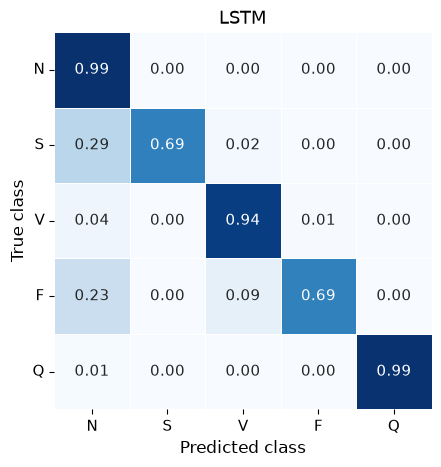

In [22]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "LSTM", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_lstm.png", dpi=200)
plt.show()

## Comparison so far (validation set)

In [23]:
pd.DataFrame([summary_row(name, m) for name, m in results.items()]).round(3)

,model,accuracy,balanced_accuracy,macro_f1,recall_S,recall_V,recall_F
0,mlp,0.981,0.870,0.904,0.708,0.934,0.727
1,simple_cnn,0.988,0.909,0.929,0.820,0.964,0.773
2,resnet_cnn,0.989,0.920,0.933,0.872,0.979,0.758
3,lstm,0.980,0.861,0.896,0.692,0.945,0.688
